In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union





Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-10/PRJNA763727/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,LibraryLayout,LibrarySelection,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,SRR15924502,AMPLICON,500,39296500,PRJNA763727,SAMN21448211,Metagenome or environmental,13844485,THE SECOND XIANGYA HOSPITAL,2021-03-01,⋯,PAIRED,PCR,METAGENOMIC,oral metagenome,ILLUMINA,2021-09-17T00:00:00Z,2021-09-16T16:59:00Z,1,G9.01,SRP337490
2,SRR15924503,AMPLICON,500,39115000,PRJNA763727,SAMN21448210,Metagenome or environmental,13632136,THE SECOND XIANGYA HOSPITAL,2021-03-01,⋯,PAIRED,PCR,METAGENOMIC,oral metagenome,ILLUMINA,2021-09-17T00:00:00Z,2021-09-16T16:59:00Z,1,G3.11,SRP337490
3,SRR15924504,AMPLICON,500,40979500,PRJNA763727,SAMN21448201,Metagenome or environmental,13697395,THE SECOND XIANGYA HOSPITAL,2021-03-01,⋯,PAIRED,PCR,METAGENOMIC,oral metagenome,ILLUMINA,2021-09-17T00:00:00Z,2021-09-16T16:59:00Z,1,G3.02,SRP337490
4,SRR15924505,AMPLICON,500,39217500,PRJNA763727,SAMN21448200,Metagenome or environmental,13246977,THE SECOND XIANGYA HOSPITAL,2021-03-01,⋯,PAIRED,PCR,METAGENOMIC,oral metagenome,ILLUMINA,2021-09-17T00:00:00Z,2021-09-16T16:59:00Z,1,G3.01,SRP337490
5,SRR15924506,AMPLICON,500,39104500,PRJNA763727,SAMN21448209,Metagenome or environmental,13216234,THE SECOND XIANGYA HOSPITAL,2021-03-01,⋯,PAIRED,PCR,METAGENOMIC,oral metagenome,ILLUMINA,2021-09-17T00:00:00Z,2021-09-16T16:59:00Z,1,G3.10,SRP337490
6,SRR15924507,AMPLICON,500,40152000,PRJNA763727,SAMN21448208,Metagenome or environmental,13381289,THE SECOND XIANGYA HOSPITAL,2021-03-01,⋯,PAIRED,PCR,METAGENOMIC,oral metagenome,ILLUMINA,2021-09-17T00:00:00Z,2021-09-16T16:59:00Z,1,G3.09,SRP337490


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "Experiment"                     "geo_loc_name_country"          
[17] "geo_loc_name_country_continent" "geo_loc_name"                  
[19] "Instrument"                     "isolation_source"              
[21] "lat_lon"                        "Library.Name"                  
[23] "LibraryLayout"                  "LibrarySelection"              
[25] "LibrarySource"                  "Organism"                      
[27] "Platform"                       "ReleaseDate"                   
[29] "create_date"                    "version"                       
[31] "Sample.Name"                    "SRA.Study"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = 'V3-V4',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = initial_meta$isolation_source,
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F:TACGGRAGGCAGCAG; R: AGGGTATCTAATCCT',
    title = "Sex Variations in the Oral Microbiomes of Youths with Severe Periodontitis",
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'NO')

In [4]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 17
[1] 17


In [5]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>
1,PRJNA763727,SRR15924502,G9.01,NA,NA,NA,V3-V4,ILLUMINA,China,subgingival plaque sample,2021-09-17T00:00:00Z,F:TACGGRAGGCAGCAG; R: AGGGTATCTAATCCT,Sex Variations in the Oral Microbiomes of Youths with Severe Periodontitis,YES,NA,NO
2,PRJNA763727,SRR15924503,G3.11,NA,NA,NA,V3-V4,ILLUMINA,China,subgingival plaque sample,2021-09-17T00:00:00Z,F:TACGGRAGGCAGCAG; R: AGGGTATCTAATCCT,Sex Variations in the Oral Microbiomes of Youths with Severe Periodontitis,YES,NA,NO
3,PRJNA763727,SRR15924504,G3.02,NA,NA,NA,V3-V4,ILLUMINA,China,subgingival plaque sample,2021-09-17T00:00:00Z,F:TACGGRAGGCAGCAG; R: AGGGTATCTAATCCT,Sex Variations in the Oral Microbiomes of Youths with Severe Periodontitis,YES,NA,NO
4,PRJNA763727,SRR15924505,G3.01,NA,NA,NA,V3-V4,ILLUMINA,China,subgingival plaque sample,2021-09-17T00:00:00Z,F:TACGGRAGGCAGCAG; R: AGGGTATCTAATCCT,Sex Variations in the Oral Microbiomes of Youths with Severe Periodontitis,YES,NA,NO
5,PRJNA763727,SRR15924506,G3.10,NA,NA,NA,V3-V4,ILLUMINA,China,subgingival plaque sample,2021-09-17T00:00:00Z,F:TACGGRAGGCAGCAG; R: AGGGTATCTAATCCT,Sex Variations in the Oral Microbiomes of Youths with Severe Periodontitis,YES,NA,NO
6,PRJNA763727,SRR15924507,G3.09,NA,NA,NA,V3-V4,ILLUMINA,China,subgingival plaque sample,2021-09-17T00:00:00Z,F:TACGGRAGGCAGCAG; R: AGGGTATCTAATCCT,Sex Variations in the Oral Microbiomes of Youths with Severe Periodontitis,YES,NA,NO


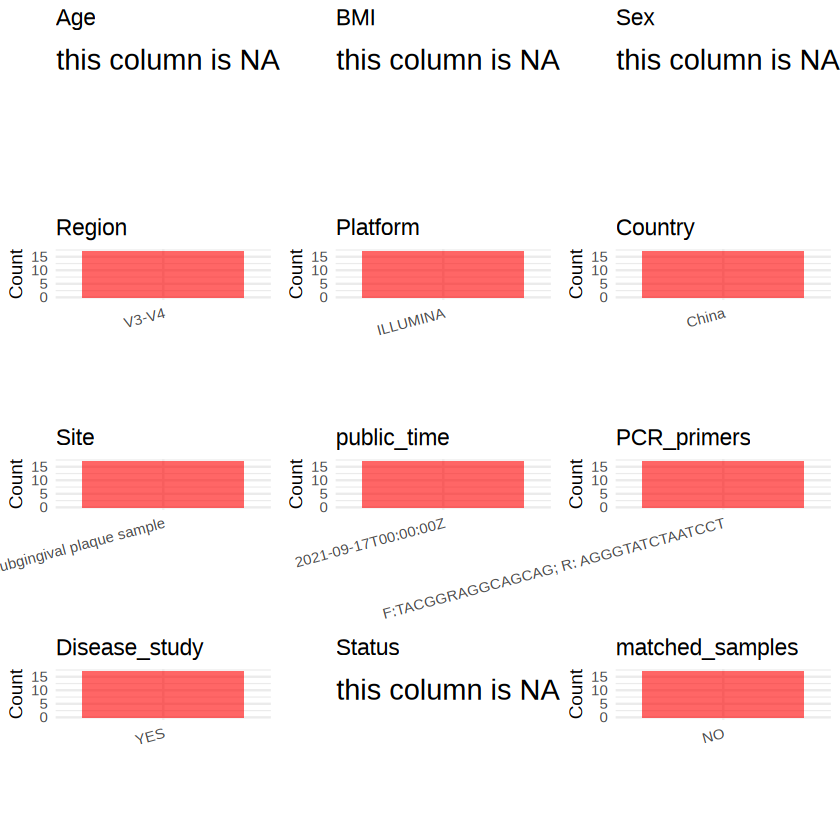

In [6]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [7]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-10/PRJNA763727/metadata.csv", quote = T)